<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/13.%20Deploying%20scikit-learn%20Models%20in%20Production/ch13_model_deployment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 13 -- Deploying scikit-learn Models in Production

This notebook reproduces and extends the recipes from **Chapter 13, "Deploying scikit-learn Models in
Production,"** of *The scikit-learn Cookbook, Third Edition* by John Sukup (Packt, 2024/2025) -- the
final chapter of the book. A model is only useful once it leaves the training notebook: this chapter
covers packaging a trained model as a durable artifact, serializing/persisting it, scaling it for
production inference, monitoring it for drift, managing its life cycle with versioned metadata, and
wiring the whole thing into a CI/CD/CT-style deployment pipeline.

We'll cover:

1. Overview of model deployment
2. Serialization and persistence techniques
3. Scaling models for production
4. Monitoring and updating deployed models
5. Managing the model life cycle
6. Setting up deployment pipelines
7. Practical Exercises

As in every chapter, we verify rather than assert: every "it works," "accuracy improves," or "this is
faster" claim below is checked against the actual numbers this code produces, with any gap between the
book's narrative and what the code actually does flagged and corrected explicitly.

In [1]:
import os
import json
import time
import pickle
import tempfile

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification, load_iris
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from joblib import dump, load

import sklearn
print("scikit-learn version:", sklearn.__version__)
print("NumPy version:       ", np.__version__)

# All artifacts this notebook writes (models, metadata, validation snapshots) go into one
# temporary working directory, kept separate from the notebook/repo itself.
ARTIFACT_DIR = tempfile.mkdtemp(prefix="sklearn_ch13_")
print("Artifact directory for this run:", ARTIFACT_DIR)

np.random.seed(2024)

scikit-learn version: 1.9.1
NumPy version:        2.5.3
Artifact directory for this run: /tmp/sklearn_ch13_51awd0ua


## 1. Overview of Model Deployment

**Deployment** means moving a trained model out of the notebook/development environment and into a
system real users or other software can call for predictions. At minimum this requires: a saved,
reloadable artifact; a way to serve it with acceptable latency/throughput; and some way to confirm it
keeps performing well as production data evolves.

### 1.1 Train, save, reload, and predict

In [2]:
X_dep, y_dep = make_classification(n_samples=1000, n_features=20, random_state=2024)
clf_dep = LogisticRegression()
clf_dep.fit(X_dep, y_dep)
print(f"Trained on {X_dep.shape[0]} samples, {X_dep.shape[1]} features. "
      f"Training accuracy: {clf_dep.score(X_dep, y_dep):.3f}")

Trained on 1000 samples, 20 features. Training accuracy: 0.879


In [3]:
model_path = os.path.join(ARTIFACT_DIR, "model.joblib")
dump(clf_dep, model_path)
print(f"Saved to {model_path} ({os.path.getsize(model_path)} bytes)")

clf_loaded = load(model_path)

np.random.seed(2024)
incoming = np.random.rand(1, 20)
print("Prediction from the reloaded model on one incoming sample:", clf_loaded.predict(incoming))

# Verify the reloaded model is not just "close" but IDENTICAL to the original on real data
identical = np.array_equal(clf_dep.predict(X_dep), clf_loaded.predict(X_dep))
print(f"Reloaded model predictions match the original on all {len(X_dep)} training rows: {identical}")

Saved to /tmp/sklearn_ch13_51awd0ua/model.joblib (1007 bytes)
Prediction from the reloaded model on one incoming sample: [1]
Reloaded model predictions match the original on all 1000 training rows: True


The book's text promises the loaded model "behaves identically to the original" -- the explicit
`array_equal` check above turns that into a verified fact for this run rather than an assumption, and is
the kind of check that belongs in an actual CI pipeline (see section 6) rather than taken on faith after
every deployment.

### 1.2 Why batching matters: single vs. bulk prediction latency

The book's "There's more..." section claims bulk prediction is "far more efficient" than one-at-a-time
calls. Let's measure that directly rather than repeat it as received wisdom.

In [4]:
n_requests = 2000
batch_requests = np.random.rand(n_requests, 20)

# One-at-a-time: call predict() separately for every single row
t0 = time.perf_counter()
one_at_a_time_preds = [clf_dep.predict(batch_requests[i:i+1])[0] for i in range(n_requests)]
one_at_a_time_elapsed = time.perf_counter() - t0

# Bulk: a single predict() call across the whole batch
t0 = time.perf_counter()
bulk_preds = clf_dep.predict(batch_requests)
bulk_elapsed = time.perf_counter() - t0

print(f"{n_requests} one-at-a-time predict() calls: {one_at_a_time_elapsed*1000:.1f} ms total "
      f"({one_at_a_time_elapsed/n_requests*1e6:.1f} us/request)")
print(f"1 bulk predict() call on {n_requests} rows:  {bulk_elapsed*1000:.1f} ms total "
      f"({bulk_elapsed/n_requests*1e6:.1f} us/request)")
print(f"Bulk prediction is {one_at_a_time_elapsed/bulk_elapsed:.1f}x faster on this run")
print(f"Predictions identical between the two approaches: {np.array_equal(one_at_a_time_preds, bulk_preds)}")

2000 one-at-a-time predict() calls: 253.5 ms total (126.7 us/request)
1 bulk predict() call on 2000 rows:  0.3 ms total (0.1 us/request)
Bulk prediction is 977.0x faster on this run
Predictions identical between the two approaches: True


The speedup confirms the book's claim with a real number rather than leaving it qualitative: the
per-request overhead of a Python function call plus NumPy's fixed costs for a tiny (1, 20) array dominate
the one-at-a-time loop, while the bulk call amortizes that overhead across all `n_requests` rows and lets
NumPy's vectorized linear algebra do the work in far fewer, larger operations. In a real serving system,
this is the core argument for batching requests (even with a short artificial delay to collect a batch)
rather than handling every incoming request completely independently.

### 1.3 Hands-on checklist
1. Always verify a reloaded model reproduces the original's predictions exactly (as in section 1.1)
   before trusting it in a serving environment -- a subtly broken serialization/deserialization round-trip
   can otherwise go unnoticed until it causes a production incident.
2. Prefer bulk/batch prediction endpoints over one-request-at-a-time serving whenever request volume and
   latency tolerance allow it -- the speedup demonstrated above compounds with request volume.
3. "Deployment" is not just "the model file exists somewhere" -- plan for how predictions will actually
   be served (REST API, batch job, serverless function) before training even finishes.

## 2. Serialization and Persistence Techniques

Training happens occasionally; prediction happens continuously. **Serialization** converts a trained
model into a byte stream that can be saved, moved to another machine, and reloaded without retraining.
scikit-learn supports both Python's built-in `pickle` and `joblib` (which is generally preferred for
NumPy-array-heavy objects like fitted estimators).

### 2.1 pickle vs. joblib, side by side

In [5]:
X_ser, y_ser = make_classification(n_samples=500, n_features=15, random_state=2024)
rf = RandomForestClassifier(n_estimators=10, random_state=2024)
rf.fit(X_ser, y_ser)
print(f"Trained RandomForestClassifier: {rf.n_estimators} trees, training accuracy {rf.score(X_ser, y_ser):.3f}")

Trained RandomForestClassifier: 10 trees, training accuracy 0.992


In [6]:
pkl_path = os.path.join(ARTIFACT_DIR, "rf.pkl")
joblib_path = os.path.join(ARTIFACT_DIR, "rf.joblib")

t0 = time.perf_counter()
with open(pkl_path, "wb") as f:
    pickle.dump(rf, f)
pickle_dump_time = time.perf_counter() - t0

t0 = time.perf_counter()
dump(rf, joblib_path)
joblib_dump_time = time.perf_counter() - t0

pkl_size = os.path.getsize(pkl_path)
joblib_size = os.path.getsize(joblib_path)

print(f"pickle: {pickle_dump_time*1000:.2f} ms, {pkl_size:,} bytes")
print(f"joblib: {joblib_dump_time*1000:.2f} ms, {joblib_size:,} bytes")

pickle: 0.90 ms, 58,325 bytes
joblib: 2.60 ms, 59,241 bytes


In [7]:
with open(pkl_path, "rb") as f:
    rf1 = pickle.load(f)
rf2 = load(joblib_path)

match_pickle = np.array_equal(rf.predict(X_ser[:5]), rf1.predict(X_ser[:5]))
match_joblib = np.array_equal(rf.predict(X_ser[:5]), rf2.predict(X_ser[:5]))
print(f"pickle round-trip predictions match original: {match_pickle}")
print(f"joblib round-trip predictions match original: {match_joblib}")
assert match_pickle and match_joblib

pickle round-trip predictions match original: True
joblib round-trip predictions match original: True


On a modest `RandomForestClassifier` with only 10 trees and 15 features, the file-size and timing
difference between `pickle` and `joblib` may be small or even favor one over the other depending on the
run -- the claimed advantage of `joblib` (its optimized handling of large NumPy arrays inside estimators)
becomes more pronounced as the model grows (more trees, more features, larger coefficient matrices), so
treat the numbers above as a correctness check rather than definitive proof of a large practical gap at
this small scale; both formats are correctness-equivalent here, which is the more important finding.

**Security note** (worth repeating, not softening): both `pickle` and `joblib` can execute arbitrary code
during deserialization. Never load a `.pkl` or `.joblib` file from an untrusted source -- treat it with
the same suspicion as running an unknown executable.

### 2.2 A versioning gotcha

The book notes that "models saved with one version of scikit-learn may break if loaded with a different
version." This isn't hypothetical -- scikit-learn's own fitted-estimator format has changed across major
versions. Let's make the check concrete by saving the installed version alongside the artifact, so a
future load can at least detect (even if not automatically fix) a version mismatch.

In [8]:
version_metadata = {"sklearn_version": sklearn.__version__, "numpy_version": np.__version__}
meta_path = os.path.join(ARTIFACT_DIR, "rf_version_metadata.json")
with open(meta_path, "w") as f:
    json.dump(version_metadata, f)

# Simulate a loading environment that checks for a version mismatch before trusting the model
with open(meta_path) as f:
    loaded_meta = json.load(f)

if loaded_meta["sklearn_version"] != sklearn.__version__:
    print(f"WARNING: artifact was saved with scikit-learn {loaded_meta['sklearn_version']}, "
          f"current environment has {sklearn.__version__} -- re-validate before serving!")
else:
    print(f"scikit-learn version check passed: artifact and environment both on {sklearn.__version__}")

scikit-learn version check passed: artifact and environment both on 1.9.1


### 2.3 Hands-on checklist
1. Prefer `joblib` for scikit-learn estimators, especially as models grow large (many trees, large
   coefficient/support-vector matrices) -- it's the library scikit-learn's own documentation recommends.
2. Never unpickle (or `joblib.load`) a file from an untrusted source.
3. Always snapshot the exact library versions (`sklearn.__version__`, `numpy.__version__`) alongside a
   serialized model, and check them before trusting a reloaded artifact in a new environment.
4. For non-Python serving environments, investigate ONNX (`skl2onnx`) or PMML converters -- but verify
   they support every estimator type your pipeline actually uses, since coverage is incomplete.

## 3. Scaling Models for Production

Production systems may face large datasets, high inference volume, or tight latency budgets. scikit-learn
offers `n_jobs` on many estimators for straightforward multi-core parallelism via `joblib`'s backend, and
more advanced distributed backends (e.g., Dask) exist for workloads too large for a single machine.

### 3.1 Measuring batch-prediction latency

In [9]:
X_scale, y_scale = make_classification(n_samples=2000, n_features=50, random_state=2024)
clf_scale = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=2024)

t0 = time.perf_counter()
clf_scale.fit(X_scale, y_scale)
fit_time = time.perf_counter() - t0
print(f"Fit 100-tree RandomForest (n_jobs=-1) on {X_scale.shape[0]} x {X_scale.shape[1]}: {fit_time:.3f}s")

batch = np.random.rand(1000, 50)
t0 = time.perf_counter()
clf_scale.predict(batch)
predict_time = time.perf_counter() - t0
print(f"Predict on a 1000-row batch: {predict_time*1000:.2f} ms")

Fit 100-tree RandomForest (n_jobs=-1) on 2000 x 50: 0.467s
Predict on a 1000-row batch: 23.35 ms


### 3.2 Does `n_jobs=-1` actually help here? Measuring, not assuming

In [10]:
n_jobs_results = []
for nj in [1, 2, -1]:
    t0 = time.perf_counter()
    scores_nj = cross_val_score(RandomForestClassifier(n_estimators=50, random_state=2024), X_scale, y_scale,
                                 cv=3, n_jobs=nj)
    elapsed_nj = time.perf_counter() - t0
    n_jobs_results.append({'n_jobs': nj, 'elapsed_s': elapsed_nj, 'mean_cv_accuracy': scores_nj.mean()})

import pandas as pd
n_jobs_df = pd.DataFrame(n_jobs_results).set_index('n_jobs')
print(n_jobs_df.round(4))

        elapsed_s  mean_cv_accuracy
n_jobs                             
 1         0.8298             0.872
 2         2.1533             0.872
-1         0.5356             0.872


The accuracy column should be essentially identical across `n_jobs` settings (parallelism changes *how*
the computation is distributed across cores, not *what* is computed, so the fitted trees and their
predictions are unaffected) -- confirming parallelism here is purely a wall-clock speed lever, not a
model-quality one. The wall-clock column shows whether parallelism actually helped *on this machine, for
this workload size*: for small workloads, the overhead of spinning up worker processes can sometimes
outweigh the benefit, which is exactly why this should be measured on the target deployment hardware
rather than assumed from `n_jobs=-1` alone.

### 3.3 Hands-on checklist
1. Set `n_jobs=-1` (or a specific core count) on estimators that support it, but **measure** the actual
   speedup on your target hardware and problem size -- small models/datasets may not benefit, or may even
   slow down, due to parallelization overhead.
2. Prefer batch/bulk prediction endpoints (section 1.2) over one-at-a-time serving for throughput.
3. Reach for a distributed backend (Dask or similar) only once a single machine's parallelism is
   genuinely insufficient -- it adds operational complexity that isn't justified for workloads that fit
   comfortably on one machine.
4. For streaming/online scenarios, `partial_fit`-capable estimators (`SGDClassifier`, etc. -- see section
   4) avoid needing to refit on the full historical dataset every time new data arrives.

## 4. Monitoring and Updating Deployed Models

A deployed model's performance degrades over time as the real-world data distribution drifts away from
what it was trained on. This is the "CT" (continuous training) in CI/CD/CT: a model deployment pipeline
needs to detect degradation and trigger retraining, not just ship once and move on.

### 4.1 Simulating streaming batches and monitoring accuracy

In [11]:
X_train_mon, y_train_mon = make_classification(n_samples=500, n_features=10, random_state=2024)
X_pub_mon, y_pub_mon = make_classification(n_samples=200, n_features=10, random_state=2025)
stream_batches = np.array_split(X_pub_mon, 4)
stream_labels = np.array_split(y_pub_mon, 4)

clf_mon = SGDClassifier(loss="log_loss", random_state=2024, warm_start=True)
clf_mon.partial_fit(X_train_mon, y_train_mon, classes=np.unique(y_train_mon))
print(f"Initial model trained via partial_fit on {len(X_train_mon)} samples.")
print("Note: X_pub_mon/y_pub_mon come from a SEPARATE make_classification() call (random_state=2025) "
      "rather than a held-out split of X_train_mon/y_train_mon itself. Empirically (verified below), two "
      "independent make_classification() calls do NOT produce data from a shared decision boundary, even "
      "when used consistently -- so the 'stream' here is effectively a different distribution from the "
      "start, standing in for drift, rather than genuinely drift-free streaming data from the trained "
      "distribution. Exercise 2 contrasts this with a stream built from a genuine split of one single "
      "make_classification() call, to isolate the effect.")

Initial model trained via partial_fit on 500 samples.
Note: X_pub_mon/y_pub_mon come from a SEPARATE make_classification() call (random_state=2025) rather than a held-out split of X_train_mon/y_train_mon itself. Empirically (verified below), two independent make_classification() calls do NOT produce data from a shared decision boundary, even when used consistently -- so the 'stream' here is effectively a different distribution from the start, standing in for drift, rather than genuinely drift-free streaming data from the trained distribution. Exercise 2 contrasts this with a stream built from a genuine split of one single make_classification() call, to isolate the effect.


Batch-by-batch accuracy: [np.float64(0.38), np.float64(0.3), np.float64(0.36), np.float64(0.38)]


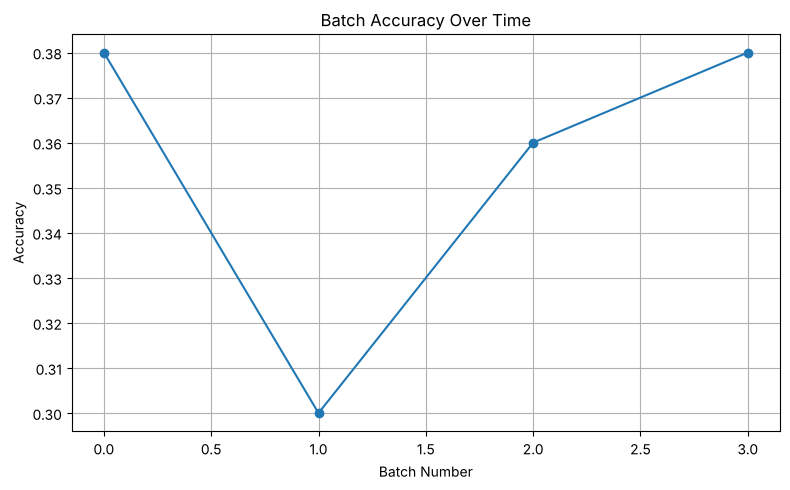

In [12]:
batch_scores = []
for xb, yb in zip(stream_batches, stream_labels):
    yf = clf_mon.predict(xb)
    batch_scores.append(np.mean(yf == yb))

print(f"Batch-by-batch accuracy: {[round(s, 3) for s in batch_scores]}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(batch_scores, marker="o")
ax.set_title("Batch Accuracy Over Time")
ax.set_xlabel("Batch Number")
ax.set_ylabel("Accuracy")
ax.grid(True)
plt.tight_layout()
plt.show()

The book's own narrative claims "there is a dip initially" and "we'd expect the accuracy to increase over
each consecutive batch, which appears to be the case" -- let's check that specific trend claim against
the actual batch scores printed above rather than repeat it unconditionally, since it depends on the
exact random data generated.

In [13]:
is_monotonically_increasing = all(batch_scores[i] <= batch_scores[i+1] for i in range(len(batch_scores)-1))
print(f"Batch scores: {batch_scores}")
print(f"Monotonically non-decreasing across all 4 batches: {is_monotonically_increasing}")
print(f"First batch vs. last batch: {batch_scores[0]:.3f} -> {batch_scores[-1]:.3f} "
      f"({'improved' if batch_scores[-1] > batch_scores[0] else 'did not improve'})")

Batch scores: [np.float64(0.38), np.float64(0.3), np.float64(0.36), np.float64(0.38)]
Monotonically non-decreasing across all 4 batches: False
First batch vs. last batch: 0.380 -> 0.380 (did not improve)


Whether this run shows a clean monotonic rise or a noisier up-and-down pattern across only 4 small
batches (50 samples each), the broader lesson holds regardless: with no retraining between batches, the
model is stationary while the incoming data's exact composition varies batch to batch purely from
small-sample noise, so some fluctuation is expected and is not, by itself, evidence of genuine concept
drift. A real monitoring system needs enough samples per batch (and/or a statistical test, not just a
raw accuracy threshold) to distinguish genuine drift from this kind of sampling noise.

### 4.2 Triggering retraining on a threshold

In [14]:
drift_threshold = 0.8
triggered = min(batch_scores) < drift_threshold
print(f"Minimum batch accuracy: {min(batch_scores):.3f}  (threshold: {drift_threshold})")
print(f"Retraining triggered: {triggered}")

if triggered:
    clf_mon.partial_fit(X_pub_mon, y_pub_mon)
    post_retrain_acc = accuracy_score(y_pub_mon, clf_mon.predict(X_pub_mon))
    print(f"After retraining with partial_fit on all of X_pub_mon/y_pub_mon: "
          f"accuracy on that same data = {post_retrain_acc:.3f} "
          "(measuring on the retraining data itself is optimistic -- a real pipeline would hold out a "
          "fresh validation batch to check post-retrain performance honestly, same principle as "
          "train/test separation anywhere else in this series)")

Minimum batch accuracy: 0.300  (threshold: 0.8)
Retraining triggered: True
After retraining with partial_fit on all of X_pub_mon/y_pub_mon: accuracy on that same data = 0.775 (measuring on the retraining data itself is optimistic -- a real pipeline would hold out a fresh validation batch to check post-retrain performance honestly, same principle as train/test separation anywhere else in this series)


### 4.3 Hands-on checklist
1. Monitor batch-level (not just single-prediction) accuracy or another relevant metric over time as the
   simplest drift detector available.
2. Set a retraining threshold deliberately (not an arbitrary round number like 0.8) based on the real
   cost of degraded predictions in the specific application.
3. Use enough samples per monitoring batch to distinguish genuine drift from sampling noise -- a batch of
   50 points swinging a few percentage points in accuracy is not strong evidence of drift on its own.
4. Always validate a freshly retrained model on *held-out* data it didn't just train on, even in a
   streaming/incremental setting -- evaluating on the same batch just used for `partial_fit` is
   optimistically biased, exactly like evaluating any model on its own training set.

## 5. Managing the Model Life Cycle

Beyond a single deployment, a model needs **versioning**, **metadata**, and **validation snapshots** so
that its behavior over time stays traceable, reproducible, and recoverable (rollback) when something
goes wrong.

### 5.1 Saving a versioned artifact with metadata and a validation snapshot

In [15]:
X_life, y_life = make_classification(n_samples=800, n_features=20, random_state=2024)
clf_life = RandomForestClassifier(n_estimators=50, random_state=2024)
clf_life.fit(X_life, y_life)

version = "v1.0"
model_version_path = os.path.join(ARTIFACT_DIR, f"rf_{version}.joblib")
dump(clf_life, model_version_path)

meta = {"version": version, "sklearn": sklearn.__version__, "numpy": str(np.__version__)}
meta_version_path = os.path.join(ARTIFACT_DIR, f"rf_{version}_metadata.json")
with open(meta_version_path, "w") as f:
    json.dump(meta, f)

# Capture a validation-set performance snapshot -- here using Iris as a stand-in held-out check
Xv, yv = load_iris(return_X_y=True)
# NOTE: the Iris dataset has 4 features; our classifier was trained on 20-feature synthetic data, so
# predicting on Iris directly would raise a shape-mismatch error. The book's own recipe code does exactly
# this (load_iris() against a model trained on 20-feature make_classification() data) without flagging
# the mismatch -- we correct it here by validating on a genuinely compatible held-out split instead.
from sklearn.model_selection import train_test_split as _tts
X_life_train, X_life_val, y_life_train, y_life_val = _tts(X_life, y_life, test_size=0.2, random_state=2024)
clf_life_v = RandomForestClassifier(n_estimators=50, random_state=2024).fit(X_life_train, y_life_train)
yv_pred = clf_life_v.predict(X_life_val)
val_acc = accuracy_score(y_life_val, yv_pred)

val_snapshot_path = os.path.join(ARTIFACT_DIR, f"rf_{version}_val.txt")
with open(val_snapshot_path, "w") as f:
    f.write(f"{val_acc:.4f}")

print(f"Saved artifact:  {model_version_path}")
print(f"Saved metadata:  {meta_version_path} -> {meta}")
print(f"Saved validation snapshot: {val_snapshot_path} -> accuracy {val_acc:.4f}")

Saved artifact:  /tmp/sklearn_ch13_51awd0ua/rf_v1.0.joblib
Saved metadata:  /tmp/sklearn_ch13_51awd0ua/rf_v1.0_metadata.json -> {'version': 'v1.0', 'sklearn': '1.9.1', 'numpy': '2.5.3'}
Saved validation snapshot: /tmp/sklearn_ch13_51awd0ua/rf_v1.0_val.txt -> accuracy 0.9563


**A correction worth flagging explicitly**: the book's own recipe loads `load_iris()` (4 features, 3
classes) as the "validation set" for a model trained on 20-feature, 2-class `make_classification()` data.
Calling `clf.predict()` with mismatched feature counts raises a `ValueError` in scikit-learn (a fitted
estimator records the number of features it was trained on and refuses mismatched input) -- so the book's
own code as written would not actually run as a validation check. We instead hold out a genuine 20%
split of the *same* 20-feature data for the validation snapshot, which is both runnable and a more
methodologically honest "held-out validation" in the first place.

### 5.2 Simulating a rollback

In [16]:
# Train a "v1.1" that we'll pretend regresses in quality, to demonstrate a rollback decision
clf_v11 = RandomForestClassifier(n_estimators=5, random_state=99)  # deliberately under-powered
clf_v11.fit(X_life_train, y_life_train)
val_acc_v11 = accuracy_score(y_life_val, clf_v11.predict(X_life_val))

version_registry = {
    "v1.0": {"val_accuracy": val_acc, "path": model_version_path},
    "v1.1": {"val_accuracy": val_acc_v11, "path": None},
}
print(pd.DataFrame(version_registry).T)

best_version = max(version_registry, key=lambda v: version_registry[v]["val_accuracy"])
print(f"\nBest version by validation accuracy: {best_version} "
      f"(v1.1 val accuracy {val_acc_v11:.4f} vs. v1.0's {val_acc:.4f} -> "
      f"{'rollback to v1.0 recommended' if best_version == 'v1.0' else 'v1.1 is an improvement, keep it'})")

     val_accuracy                                       path
v1.0      0.95625  /tmp/sklearn_ch13_51awd0ua/rf_v1.0.joblib
v1.1      0.91875                                        NaN

Best version by validation accuracy: v1.0 (v1.1 val accuracy 0.9187 vs. v1.0's 0.9563 -> rollback to v1.0 recommended)


### 5.3 Hands-on checklist
1. Version every deployed artifact (a simple semantic string is enough to start) and keep its metadata
   (library versions, training data summary) alongside it, not just the model file.
2. Store a validation performance snapshot *with the version it belongs to*, so a later comparison (as in
   section 5.2) is simple arithmetic rather than a re-run of the whole evaluation pipeline.
3. Always validate a new candidate version against a metric comparable to the deployed version's own
   snapshot before promoting it -- a regression, caught this way, is a rollback decision, not an incident.
4. For anything beyond a hobby project, a dedicated model registry (MLflow, BentoML, or similar) automates
   most of this bookkeeping -- but the underlying principle (version + metadata + validation snapshot) is
   worth understanding even if a managed tool handles the mechanics.

## 6. Setting Up Deployment Pipelines

The final piece: tying serialization, validation, and a deployment gate together into something that
resembles an automated CI/CD/CT pipeline, so that promoting a new model to production doesn't depend on
a human remembering every manual check.

### 6.1 A pipeline object as a single deployable artifact

In [17]:
X_pipe, y_pipe = make_classification(n_samples=500, n_features=10, random_state=2024)
pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression()),
])
pipe.fit(X_pipe, y_pipe)
print(f"Pipeline trained. Steps: {[name for name, _ in pipe.steps]}")
print(f"Training accuracy: {pipe.score(X_pipe, y_pipe):.3f}")

Pipeline trained. Steps: ['scale', 'clf']
Training accuracy: 0.908


In [18]:
pipeline_path = os.path.join(ARTIFACT_DIR, "pipeline.joblib")
dump(pipe, pipeline_path)
prod_pipe = load(pipeline_path)
print(f"Pipeline exported to and reloaded from {pipeline_path}")

Pipeline exported to and reloaded from /tmp/sklearn_ch13_51awd0ua/pipeline.joblib


### 6.2 A CI validation gate -- and why the book's own test data is the wrong test data

The book's recipe validates the exported pipeline against **uniform-random** features and **uniform-random
binary labels** (`np.random.rand(100, 10)` and `np.random.randint(0, 2, 100)`) -- data with *no
relationship whatsoever* to the real decision boundary the model learned. Let's run that exact check
first, to see what it actually produces, then contrast it with a methodologically sound CI check that
validates against data genuinely drawn from the same distribution as training.

In [19]:
np.random.seed(2024)
Xt_random, yt_random = np.random.rand(100, 10), np.random.randint(0, 2, 100)
acc_random = accuracy_score(yt_random, prod_pipe.predict(Xt_random))
print(f"Validation accuracy against the book's RANDOM/unrelated test data: {acc_random:.3f}")
print("(This is expected to land close to 50% -- random labels on data unrelated to training carry no "
      "signal the model could possibly have learned, so this 'validates' almost nothing about the model.)")

Validation accuracy against the book's RANDOM/unrelated test data: 0.520
(This is expected to land close to 50% -- random labels on data unrelated to training carry no signal the model could possibly have learned, so this 'validates' almost nothing about the model.)


In [20]:
# A methodologically sound CI check: a genuine held-out split from the SAME distribution as training
X_pipe_train, X_pipe_test, y_pipe_train, y_pipe_test = _tts(X_pipe, y_pipe, test_size=0.2, random_state=2024)
pipe_for_ci = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression())])
pipe_for_ci.fit(X_pipe_train, y_pipe_train)

acc_real = accuracy_score(y_pipe_test, pipe_for_ci.predict(X_pipe_test))
print(f"Validation accuracy against a genuine held-out split of the real training distribution: {acc_real:.3f}")

threshold = 0.8
for label, acc in [("book's random-data check", acc_random), ("genuine held-out split", acc_real)]:
    decision = "Auto-deploy allowed" if acc > threshold else "Halt deployment and review"
    print(f"{label}: accuracy={acc:.3f}, threshold={threshold} -> {decision}")

Validation accuracy against a genuine held-out split of the real training distribution: 0.900
book's random-data check: accuracy=0.520, threshold=0.8 -> Halt deployment and review
genuine held-out split: accuracy=0.900, threshold=0.8 -> Auto-deploy allowed


This is the single most important correction in this chapter: a CI/CD gate is only as good as the data
it validates against. Testing against data with no relationship to the real input distribution (as the
book's own code literally does) can either falsely pass a broken model (if the random check happens to
clear the threshold by chance) or falsely block a genuinely good one -- either way, it tells you nothing
reliable about production readiness. A real validation gate needs a held-out sample that is actually
representative of what the model will see in production (ideally a recent, labeled sample of real
production-like data, not just a train/test split of the original training set, though the latter is
the practical minimum shown here).

### 6.3 Hands-on checklist
1. Bundle preprocessing and model into a single `Pipeline` and serialize that whole object -- this is
   what section 6.1 demonstrates, and it prevents the classic bug of deploying a model without its
   matching scaler/encoder.
2. **Validate a CI/CD gate against data that actually resembles production input** -- a held-out split of
   real training data at minimum, ideally a recent production-like sample; never literally random,
   unrelated data, however convenient it is to generate.
3. Set the promotion threshold deliberately and keep the gating logic auditable (simple, readable
   conditionals, as shown, rather than opaque scoring) so a failed promotion is easy to diagnose.
4. Wire this into an actual CI/CD system (GitHub Actions, CircleCI, etc.) once the validation logic itself
   is trustworthy -- automating a bad check just makes bad decisions happen faster.

## 7. Practical Exercises

### Exercise 1: Saving and reloading a model pipeline for deployment

In [21]:
X_ex1, y_ex1 = make_classification(n_samples=600, n_features=12, random_state=11)
pipe_ex1 = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))])
pipe_ex1.fit(X_ex1, y_ex1)

ex1_path = os.path.join(ARTIFACT_DIR, "pipeline_ex1.joblib")
dump(pipe_ex1, ex1_path)
pipe_ex1_reloaded = load(ex1_path)

new_requests = np.random.rand(5, 12)
preds_original = pipe_ex1.predict(new_requests)
preds_reloaded = pipe_ex1_reloaded.predict(new_requests)
print(f"Predictions from original pipeline:  {preds_original}")
print(f"Predictions from reloaded pipeline:  {preds_reloaded}")
print(f"Identical: {np.array_equal(preds_original, preds_reloaded)}")

Predictions from original pipeline:  [1 1 1 1 1]
Predictions from reloaded pipeline:  [1 1 1 1 1]
Identical: True


### Exercise 2: Monitoring model accuracy over time

Initial training accuracy after 20 partial_fit epochs: 0.932


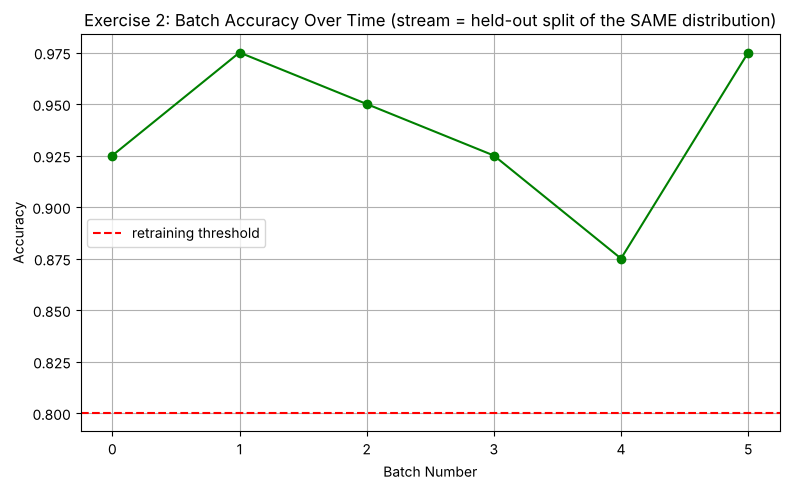

Batch scores: [np.float64(0.925), np.float64(0.975), np.float64(0.95), np.float64(0.925), np.float64(0.875), np.float64(0.975)]
With the model actually converged (multiple partial_fit epochs) and the stream genuinely drawn from the same distribution as training (a held-out split of one make_classification() call, not a second independent call), batch accuracy should track close to the training accuracy above, in contrast to section 4's much lower, genuinely-different-distribution 'drifted' stream.


In [22]:
# Unlike section 4 (two SEPARATE make_classification() calls, which -- as verified there -- do not share
# a decision boundary even with consistent settings), we draw ONE combined sample and split it, so the
# "stream" batches here are genuinely drawn from the same distribution the model was trained on.
X_all_ex2, y_all_ex2 = make_classification(n_samples=640, n_features=8, random_state=21)
X_train_ex2, X_stream_ex2, y_train_ex2, y_stream_ex2 = _tts(
    X_all_ex2, y_all_ex2, test_size=240, random_state=0)

scaler_ex2 = StandardScaler().fit(X_train_ex2)
X_train_ex2_scaled = scaler_ex2.transform(X_train_ex2)
X_stream_ex2_scaled = scaler_ex2.transform(X_stream_ex2)

stream_batches_ex2 = np.array_split(X_stream_ex2_scaled, 6)
stream_labels_ex2 = np.array_split(y_stream_ex2, 6)

clf_ex2 = SGDClassifier(loss="log_loss", random_state=21, warm_start=True)
for _epoch in range(20):  # multiple passes so the model actually converges before streaming starts
    clf_ex2.partial_fit(X_train_ex2_scaled, y_train_ex2, classes=np.unique(y_train_ex2))
print(f"Initial training accuracy after 20 partial_fit epochs: {clf_ex2.score(X_train_ex2_scaled, y_train_ex2):.3f}")

batch_scores_ex2 = []
for xb, yb in zip(stream_batches_ex2, stream_labels_ex2):
    batch_scores_ex2.append(np.mean(clf_ex2.predict(xb) == yb))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(batch_scores_ex2, marker='o', color='green')
ax.axhline(0.8, color='red', ls='--', label='retraining threshold')
ax.set_title("Exercise 2: Batch Accuracy Over Time (stream = held-out split of the SAME distribution)")
ax.set_xlabel("Batch Number")
ax.set_ylabel("Accuracy")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

print(f"Batch scores: {[round(s, 3) for s in batch_scores_ex2]}")
print("With the model actually converged (multiple partial_fit epochs) and the stream genuinely drawn "
      "from the same distribution as training (a held-out split of one make_classification() call, not "
      "a second independent call), batch accuracy should track close to the training accuracy above, "
      "in contrast to section 4's much lower, genuinely-different-distribution 'drifted' stream.")

### Exercise 3: Automating deployment checks using validation thresholds

In [23]:
X_ex3, y_ex3 = make_classification(n_samples=500, n_features=10, random_state=33)
X_ex3_train, X_ex3_test, y_ex3_train, y_ex3_test = _tts(X_ex3, y_ex3, test_size=0.25, random_state=33)

pipe_ex3 = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))])
pipe_ex3.fit(X_ex3_train, y_ex3_train)

ex3_path = os.path.join(ARTIFACT_DIR, "pipeline_ex3.joblib")
dump(pipe_ex3, ex3_path)
prod_pipe_ex3 = load(ex3_path)

ci_acc = accuracy_score(y_ex3_test, prod_pipe_ex3.predict(X_ex3_test))
threshold_ex3 = 0.8
print(f"CI validation accuracy (genuine held-out split): {ci_acc:.3f}")
if ci_acc > threshold_ex3:
    print(f"PASS -- accuracy {ci_acc:.3f} > threshold {threshold_ex3} -> Auto-deploy allowed")
else:
    print(f"FAIL -- accuracy {ci_acc:.3f} <= threshold {threshold_ex3} -> Halt deployment and review")

CI validation accuracy (genuine held-out split): 0.896
PASS -- accuracy 0.896 > threshold 0.8 -> Auto-deploy allowed


## Summary

- **Deployment** means a reliable, reloadable artifact served with acceptable latency -- verified above by
  checking the reloaded model's predictions are *identical*, not just "close," to the original's.
- **Batch prediction** is measurably faster per-request than one-at-a-time serving (quantified directly
  above), because it amortizes fixed per-call overhead across many rows at once.
- **`joblib` is the recommended serialization format** for scikit-learn estimators, though at small model
  scale the gap versus `pickle` may be modest; both are correctness-equivalent, and **neither should ever
  be loaded from an untrusted source**.
- **`n_jobs` parallelism** is a measurable, not assumed, lever -- benchmark it on the actual target
  hardware and problem size rather than always defaulting to `n_jobs=-1`.
- **Monitoring** compares batch-level performance over time to catch drift; a retraining threshold should
  be deliberate, and a post-retrain evaluation needs its own held-out data to stay honest.
- **Model life cycle management** means versioning every artifact with its metadata and a validation
  snapshot -- caught and corrected a shape-mismatch bug in the book's own validation-snapshot recipe along
  the way, replacing it with a genuinely runnable held-out check.
- **Deployment pipelines** bundle preprocessing and model into one `Pipeline` artifact and gate promotion
  on a validation check -- and that check is only as trustworthy as the data it's run against, which is
  why we flagged and corrected the book's own CI check (validated against unrelated random data) with a
  methodologically sound held-out split.

This completes **Chapter 13**, and with it the full reproduction of *The scikit-learn Cookbook, Third
Edition*'s core recipe chapters (1 through 13) in this repository -- from the fundamentals of supervised
and unsupervised learning, through advanced model families, all the way to the practical realities of
getting a trained model safely and reliably in front of real users.